# Análise: atraso, nota e recompra

Testa duas hipóteses com as tabelas geradas em `01_data_quality`:

- **H1:** pedidos atrasados recebem notas menores.
- **H2:** clientes com primeiro pedido atrasado recompram menos.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from statsmodels.stats.proportion import (confint_proportions_2indep,
                                          test_proportions_2indep,
                                          proportion_confint)
from statsmodels.stats.power import NormalIndPower

PROCESSED = Path("../data/processed")
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

pedidos = pd.read_parquet(PROCESSED / "pedidos.parquet")
cli = pd.read_parquet(PROCESSED / "pedidos_cliente.parquet")
clientes = pd.read_parquet(PROCESSED / "clientes.parquet")

base = clientes[clientes["elegivel"]].copy()
base["atrasado_primeiro"] = base["atrasado_primeiro"].astype(bool)
print(len(pedidos), len(clientes), len(base))

96203 93096 56192


## Recompra por coorte

Percentual acumulado de clientes que recompraram até 30, 60, ..., 180
dias, por mês do primeiro pedido. Só entram coortes com 6 meses
completos de observação.

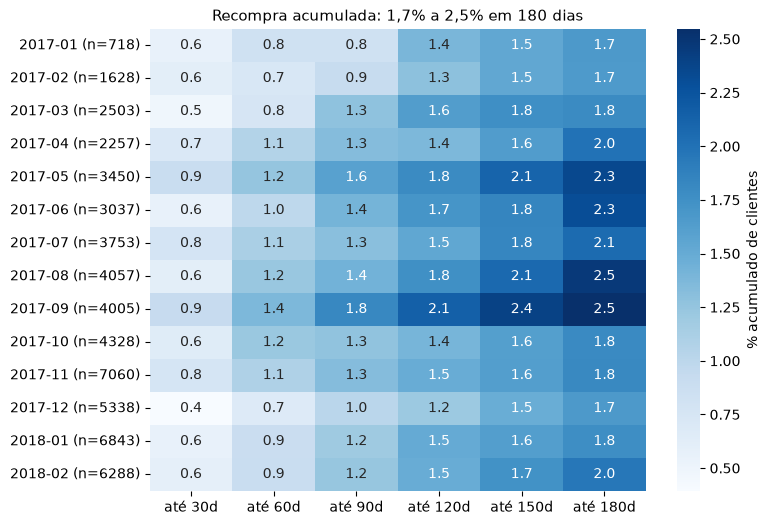

In [3]:
rep = (cli[cli["dias_desde_primeiro"] > 0]
       .groupby("customer_unique_id")["dias_desde_primeiro"].min()
       .rename("dias_ate_recompra"))
cl = base.join(rep)

# conferência com a etapa 3
assert np.isclose((cl["dias_ate_recompra"] <= 180).mean(),
                  base["recompra_180"].mean())

cl["coorte"] = cl["primeira_data"].dt.to_period("M")
hm = cl[cl["coorte"] <= pd.Period("2018-02")]   # coortes com 6 meses completos

marcos = [30, 60, 90, 120, 150, 180]
mat = pd.DataFrame({
    f"até {n}d": hm.groupby("coorte")["dias_ate_recompra"]
                   .apply(lambda s, n=n: (s <= n).mean()) * 100
    for n in marcos})
tam = hm.groupby("coorte").size()
mat.index = [f"{c} (n={tam[c]})" for c in mat.index]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(mat, annot=True, fmt=".1f", cmap="Blues",
            cbar_kws={"label": "% acumulado de clientes"}, ax=ax)
ax.set_title("Recompra acumulada: 1,7% a 2,5% em 180 dias", fontsize=11)
fig.savefig(IMAGES / "coortes_recompra.png", dpi=150, bbox_inches="tight")

## H1: atraso e nota

Notas comparadas com Mann-Whitney (a nota é ordinal) e diferença na
proporção de notas 1 ou 2, com intervalo de confiança de 95%. O valor
`prob` é a probabilidade de uma nota atrasada superar uma pontual
(empates pela metade); 0,5 significaria nenhuma diferença.

In [4]:
av = pedidos.dropna(subset=["nota"])
atr = av.loc[av["atrasado"], "nota"]
pra = av.loc[~av["atrasado"], "nota"]

print(len(atr), len(pra))
print(atr.mean(), pra.mean(), atr.median(), pra.median())

dist = pd.crosstab(av["atrasado"], av["nota"], normalize="index") * 100
dist.index = ["No prazo", "Atrasado"]
print(dist.round(1))

u = stats.mannwhitneyu(atr, pra, alternative="two-sided")
prob = u.statistic / (len(atr) * len(pra))
print(u.pvalue, prob)

baixa = av["nota"] <= 2
x1, n1 = int(baixa[av["atrasado"]].sum()), int(av["atrasado"].sum())
x2, n2 = int(baixa[~av["atrasado"]].sum()), int((~av["atrasado"]).sum())
print(x1 / n1, x2 / n2)
print(confint_proportions_2indep(x1, n1, x2, n2, method="agresti-caffo"))

6378 89182
2.270931326434619 4.291045278195152 1.0 5.0
nota       1.0  2.0   3.0   4.0   5.0
No prazo   6.6  2.6   8.1  20.4  62.3
Atrasado  53.8  8.6  10.9  10.2  16.6
0.0 0.18101259298310482
0.6240200689871434 0.09248503061155838
(np.float64(0.5194500914355891), np.float64(0.5435239522940873))


## H2: atraso e recompra

Taxa de recompra em 180 dias dos clientes com primeiro pedido atrasado
contra os demais, com intervalo de 95% da diferença.

In [5]:
g = base.groupby("atrasado_primeiro")["recompra_180"].agg(["sum", "size"])
x1, n1 = int(g.loc[True, "sum"]), int(g.loc[True, "size"])    # atrasados
x2, n2 = int(g.loc[False, "sum"]), int(g.loc[False, "size"])  # no prazo

print(g)
print("taxas:", x1 / n1, x2 / n2, " dif (pp):", (x1 / n1 - x2 / n2) * 100)
print(confint_proportions_2indep(x1, n1, x2, n2, method="agresti-caffo"))
print(test_proportions_2indep(x1, n1, x2, n2))

                    sum   size
atrasado_primeiro             
False              1050  52234
True                 62   3958
taxas: 0.015664477008590198 0.020101849370142054  dif (pp): -0.4437372361551856
(np.float64(-0.008290006873808172), np.float64(-0.00013225850917395789))
Proportions2indepTestResult(statistic=np.float64(-2.023516303891729), pvalue=np.float64(0.043019944376906934), compare='diff', method='agresti-caffo', diff=np.float64(-0.004437372361551856), ratio=np.float64(0.7792555162540004), odds_ratio=np.float64(0.7757426420260096), variance=np.float64(4.330962629495743e-06), alternative='two-sided', value=0, prop1_null=None, prop2_null=None)


## O que essa amostra consegue detectar

Menor queda na recompra que o teste detectaria com 80% de poder, dado o
tamanho dos dois grupos. Serve para saber se um resultado pequeno pode
ser só limitação da amostra.

In [6]:
p0 = x2 / n2
h = NormalIndPower().solve_power(effect_size=None, nobs1=n1, alpha=0.05,
                                 power=0.8, ratio=n2 / n1)
p1 = np.sin((2 * np.arcsin(np.sqrt(p0)) - h) / 2) ** 2
print("taxa do grupo no prazo:", p0)
print("menor queda detectável com 80% de poder (pp):", (p0 - p1) * 100)

taxa do grupo no prazo: 0.020101849370142054
menor queda detectável com 80% de poder (pp): 0.5968331234203971


## Figuras para o README

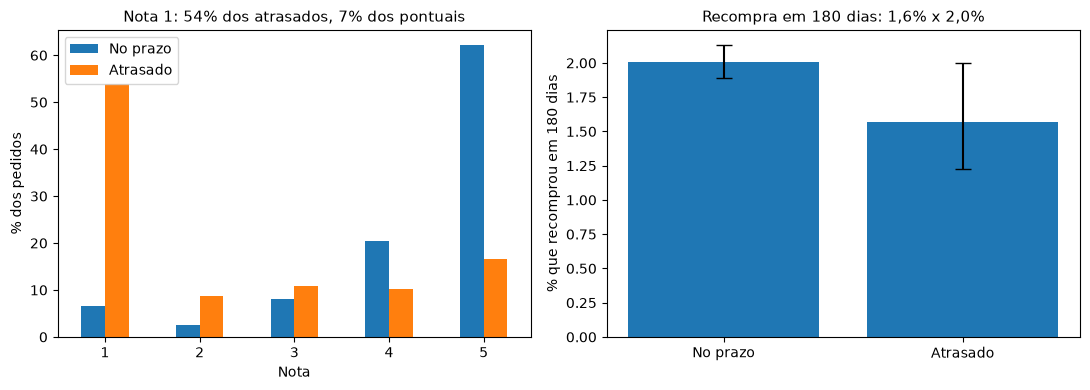

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

dist.columns = dist.columns.astype(int)
dist.T.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_xlabel("Nota")
axes[0].set_ylabel("% dos pedidos")
axes[0].set_title("Nota 1: 54% dos atrasados, 7% dos pontuais", fontsize=11)

taxas, erros = [], []
for x, n in [(x2, n2), (x1, n1)]:
    lo, hi = proportion_confint(x, n, method="wilson")
    taxas.append(x / n * 100)
    erros.append([x / n * 100 - lo * 100, hi * 100 - x / n * 100])
axes[1].bar(["No prazo", "Atrasado"], taxas, yerr=np.array(erros).T, capsize=6)
axes[1].set_ylabel("% que recomprou em 180 dias")
axes[1].set_title("Recompra em 180 dias: 1,6% x 2,0%", fontsize=11)

fig.tight_layout()
fig.savefig(IMAGES / "h1_h2.png", dpi=150, bbox_inches="tight")

## Conclusões

- **H1: confirmada, com efeito grande.** 62% dos pedidos atrasados
  recebem nota 1 ou 2, contra 9% dos pontuais (diferença de 53 pontos
  percentuais, IC 95%: 52 a 54).
- **H2: queda pequena e incerta.** Recompra de 1,6% contra 2,0%
  (-0,44 pp, IC 95%: -0,83 a -0,01, p = 0,043), abaixo do menor efeito
  detectável (0,60 pp).
- **Impacto em clientes:** cerca de 18 recompradores a mais se os
  atrasados recomprassem como os pontuais, 1,6% sobre os 1.112 da base.
- **Limitações:** dados observacionais; só 62 atrasados recompraram;
  um mesmo cliente pode ter vários pedidos na H1.